
# Phase 5 - Super-Clustering Contextual v5.2 (Pretrained Chronos Embeddings)

Objetivo: probar un modelo **preentrenado** (Chronos T5) para extraer embeddings de ventanas
sin entrenamiento adicional, y comparar contra `v5.1` con el mismo esquema de evaluación OOS.

Pipeline:
1. Construir ventanas de `move_pips` (longitud 32) desde segmentos GBPUSD.
2. Extraer embeddings con `amazon/chronos-t5-small` usando `ChronosPipeline.embed`.
3. Evaluar candidatos de embedding (`raw`, `zscore`) con selección de `K` walk-forward en train+val.
4. Entrenar KMeans final en train+val y perfilar en test.
5. Comparar métricas con `v2`, `v5.1` y `v5`.


DEVICE = cuda
MODEL_ID = amazon/chronos-t5-small
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_2_chronos_pretrained
windows built from segments = 1605
split counts: {'train': 1123, 'val': 241, 'test': 241}


chronos context length = 512


chronos_raw_clip -> (1605, 512)


chronos_zscore -> (1605, 512)


best embedding candidate = chronos_raw_clip
BEST_K = 11


...

/tmp/ipykernel_164146/46446808.py:291: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_164146/46446808.py:291: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_164146/46446808.py:291: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfr

/tmp/ipykernel_164146/46446808.py:291: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_164146/46446808.py:291: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_164146/46446808.py:291: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfr

saved summary = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_2_chronos_pretrained/GBPUSD_superclustering_summary_v5_2.json
test -> kw_p: 0.0003385125124895775 | anova_p: 0.003918868423364127 | eta2: 0.08201481522967172


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,2,49,-19.700041,-30.800104,100.279711,-0.196451
1,6,49,33.926550,51.500797,116.752499,0.290585
2,7,44,-47.563477,-40.799975,84.079632,-0.565696
3,0,22,39.449876,34.649968,88.103156,0.447769
4,4,22,-6.431829,-12.849569,215.370879,-0.029864
5,8,21,-50.266811,-67.000389,101.655294,-0.494483
6,3,17,0.300057,9.399652,96.068078,0.003123
7,9,11,-25.172992,11.199713,73.403127,-0.342942
8,1,6,72.016716,43.849945,81.768488,0.880739


,model,best_k,kw_pvalue_test,anova_pvalue_test,eta2_test
0,v2,6,0.004396,0.004857,0.063914
1,v5_improved,10,0.023002,0.012388,0.060452
2,v5_1_kwalk,7,0.003426,0.001840,0.076161
3,v5_2_chronos_pretrained,11,0.000339,0.003919,0.082015


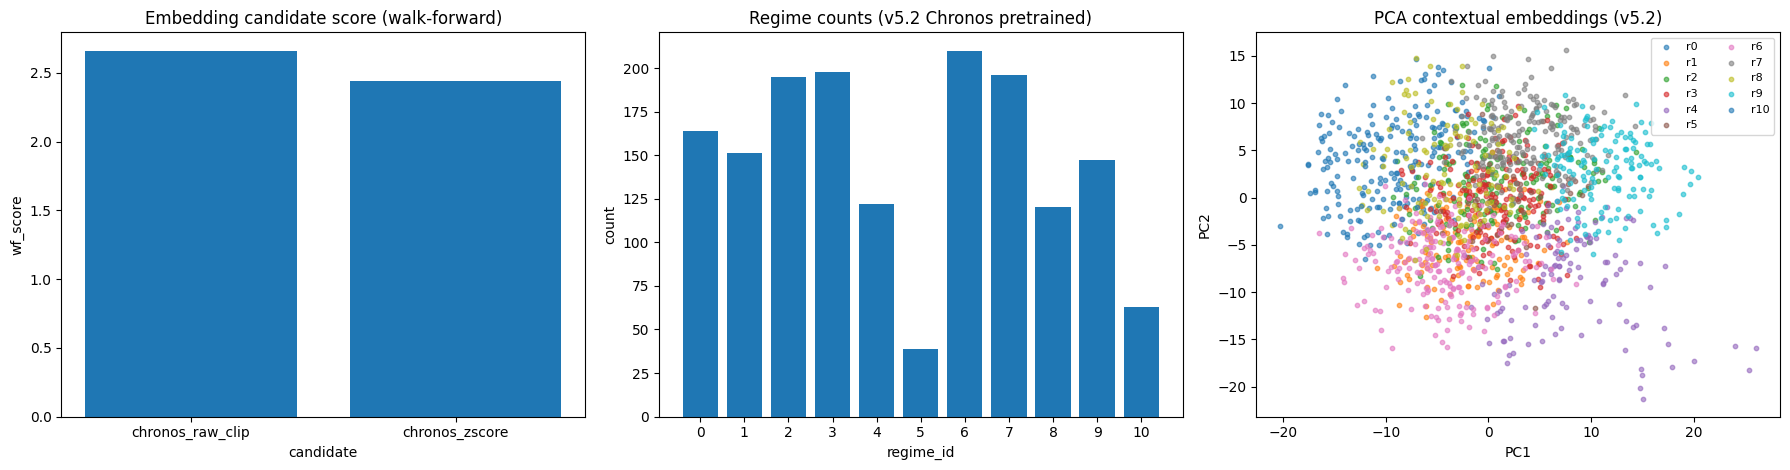

In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from chronos import ChronosPipeline

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 340)

# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_ID = 'amazon/chronos-t5-small'

K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
N_INIT_KMEANS = 50
MIN_CLUSTER_N_FOLD = 15
MIN_CLUSTER_N_TEST = 20

# walk-forward folds sobre train+val (expanding)
FOLD_SPECS = [
    (0.50, 0.10),
    (0.60, 0.10),
    (0.70, 0.10),
    (0.80, 0.10),
]

BATCH_EMB = 128

ROOT = Path('./phases/phase05_context_sequencing')
SEG_PATH = Path('./phases/phase04_transfer_clustering/output_transfer_GBPUSD_full_v2/GBPUSD_segment_cluster_assignments.parquet')
V2_EMB_PATH = ROOT / 'output_superclustering_contextual_GBPUSD_v2/GBPUSD_context_window_embeddings.parquet'

OUT_DIR = ROOT / 'output_superclustering_contextual_GBPUSD_v5_2_chronos_pretrained'
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAND_SEL_CSV = OUT_DIR / 'GBPUSD_pretrained_embedding_candidates_v5_2.csv'
K_SEL_CSV = OUT_DIR / 'GBPUSD_k_selection_walkforward_v5_2.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings_v5_2.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings_v5_2.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile_v5_2.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix_v5_2.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary_v5_2.json'

V2_SUM = ROOT / 'output_superclustering_contextual_GBPUSD_v2/GBPUSD_superclustering_summary.json'
V5_SUM = ROOT / 'output_superclustering_contextual_GBPUSD_v5_improved/GBPUSD_superclustering_summary_v5.json'
V51_SUM = ROOT / 'output_superclustering_contextual_GBPUSD_v5_kwalk/GBPUSD_superclustering_summary_v5_1.json'

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('DEVICE =', DEVICE)
print('MODEL_ID =', MODEL_ID)
print('OUT_DIR =', OUT_DIR)

# =========================
# Load metadata / build windows
# =========================
seg = pd.read_parquet(SEG_PATH).copy()
seg['start_ts'] = pd.to_datetime(seg['start_ts'], errors='coerce')
seg = seg.sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
seg['move_pips'] = pd.to_numeric(seg['move_pips'], errors='coerce').fillna(0.0).astype(float)

rows = []
moves = seg['move_pips'].to_numpy(dtype=float)
starts = seg['start_ts'].to_numpy(dtype='datetime64[ns]')
for i in range(0, len(seg) - SEQ_LEN + 1):
    m = moves[i:i+SEQ_LEN]
    rows.append({
        'window_id': int(i),
        'start_ts': pd.Timestamp(starts[i]),
        'end_ts': pd.Timestamp(starts[i+SEQ_LEN-1]),
        'move_seq': m.astype(np.float32),
    })
W = pd.DataFrame(rows)
print('windows built from segments =', len(W))

# Use split + target return from v2 to keep exact comparability
V2 = pd.read_parquet(V2_EMB_PATH)[['window_id', 'start_ts', 'end_ts', 'split', 'ret_fwd_24h_pips']].copy()
V2['start_ts'] = pd.to_datetime(V2['start_ts'], errors='coerce')
V2['end_ts'] = pd.to_datetime(V2['end_ts'], errors='coerce')

M = W.merge(V2, on=['window_id', 'start_ts', 'end_ts'], how='inner')
assert len(M) == len(V2), f'merge mismatch: {len(M)} vs {len(V2)}'

# deterministic order
M = M.sort_values('window_id').reset_index(drop=True)

idx_tr = np.where(M['split'].to_numpy() == 'train')[0]
idx_va = np.where(M['split'].to_numpy() == 'val')[0]
idx_te = np.where(M['split'].to_numpy() == 'test')[0]
idx_tv = np.concatenate([idx_tr, idx_va])

ret = pd.to_numeric(M['ret_fwd_24h_pips'], errors='coerce').to_numpy(dtype=float)

print('split counts:', M['split'].value_counts().to_dict())

# =========================
# Pretrained Chronos embeddings
# =========================
pipe = ChronosPipeline.from_pretrained(
    MODEL_ID,
    device_map='cuda' if DEVICE == 'cuda' else 'cpu',
)
print('chronos context length =', pipe.model_context_length)

X_raw = np.vstack(M['move_seq'].to_numpy())  # [N, L]

# robust clip from train only
a = X_raw[idx_tr].reshape(-1)
clip_lo = np.quantile(a, 0.01)
clip_hi = np.quantile(a, 0.99)
X_clip = np.clip(X_raw, clip_lo, clip_hi)

# candidate A: raw-clipped
X_a = X_clip.astype(np.float32)

# candidate B: per-window zscore on clipped data
mu = X_clip.mean(axis=1, keepdims=True)
sd = X_clip.std(axis=1, keepdims=True)
X_b = ((X_clip - mu) / (sd + 1e-6)).astype(np.float32)

candidates = {
    'chronos_raw_clip': X_a,
    'chronos_zscore': X_b,
}

@torch.no_grad()
def chronos_embed_matrix(X: np.ndarray, batch_size: int = 128):
    embs = []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i+batch_size], dtype=torch.float32)
        h, _ = pipe.embed(xb)
        # h: [B, L+1, D]. mean-pool over temporal tokens (exclude first token)
        z = h[:, 1:, :].mean(dim=1)
        embs.append(z.detach().cpu().numpy().astype(np.float32))
    return np.vstack(embs)

emb_map = {}
for name, X in candidates.items():
    Z = chronos_embed_matrix(X, batch_size=BATCH_EMB)
    emb_map[name] = Z
    print(name, '->', Z.shape)

# =========================
# Helpers for evaluation
# =========================
def zcol(s):
    s = pd.to_numeric(s, errors='coerce')
    m = float(s.mean())
    sd = float(s.std(ddof=0))
    if not np.isfinite(sd) or sd < 1e-9:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - m) / (sd + 1e-9)


def build_folds(idx_tv):
    n = len(idx_tv)
    folds = []
    for tr_r, va_r in FOLD_SPECS:
        tr_end = int(n * tr_r)
        va_end = min(n, int(n * (tr_r + va_r)))
        if va_end - tr_end < 30:
            continue
        folds.append((idx_tv[:tr_end], idx_tv[tr_end:va_end]))
    return folds


def evaluate_k_walkforward(Z: np.ndarray, ret: np.ndarray, idx_tv: np.ndarray):
    folds = build_folds(idx_tv)
    rows = []
    for k in K_CANDIDATES:
        fold_eta2 = []
        fold_kw = []
        fold_sil = []
        fold_ch = []
        fold_db = []
        fold_ari = []

        for tr_idx, va_idx in folds:
            sc = StandardScaler()
            Ztr = sc.fit_transform(Z[tr_idx])
            Zva = sc.transform(Z[va_idx])

            seed_labels = {}
            sils, chs, dbs = [], [], []
            for sd in KMEANS_SEEDS:
                km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
                km.fit(Ztr)
                lv = km.predict(Zva)
                seed_labels[sd] = lv
                if len(np.unique(lv)) >= 2 and len(lv) > k:
                    sils.append(float(silhouette_score(Zva, lv)))
                    chs.append(float(calinski_harabasz_score(Zva, lv)))
                    dbs.append(float(davies_bouldin_score(Zva, lv)))

            aris = []
            keys = list(seed_labels.keys())
            for i in range(len(keys)):
                for j in range(i + 1, len(keys)):
                    aris.append(float(adjusted_rand_score(seed_labels[keys[i]], seed_labels[keys[j]])))

            lv = seed_labels[42]
            rv = ret[va_idx]
            ok = np.isfinite(rv)
            rv = rv[ok]
            lv = lv[ok]

            groups = []
            for cid in np.unique(lv):
                g = rv[lv == cid]
                if len(g) >= MIN_CLUSTER_N_FOLD:
                    groups.append(g)

            if len(groups) >= 2:
                kw = float(kruskal(*groups).pvalue)
                all_vals = np.concatenate(groups)
                gm = np.mean(all_vals)
                ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
                sst = np.sum((all_vals - gm) ** 2)
                eta2 = float(ssb / sst) if sst > 0 else np.nan
                fold_kw.append(kw)
                fold_eta2.append(eta2)

            if sils:
                fold_sil.append(float(np.mean(sils)))
            if chs:
                fold_ch.append(float(np.mean(chs)))
            if dbs:
                fold_db.append(float(np.mean(dbs)))
            if aris:
                fold_ari.append(float(np.mean(aris)))

        rows.append({
            'k': int(k),
            'folds_used': int(len(fold_eta2)),
            'eta2_wf_mean': float(np.nanmean(fold_eta2)) if fold_eta2 else np.nan,
            'eta2_wf_median': float(np.nanmedian(fold_eta2)) if fold_eta2 else np.nan,
            'kw_wf_mean': float(np.nanmean(fold_kw)) if fold_kw else np.nan,
            'sil_wf_mean': float(np.nanmean(fold_sil)) if fold_sil else np.nan,
            'ch_wf_mean': float(np.nanmean(fold_ch)) if fold_ch else np.nan,
            'db_wf_mean': float(np.nanmean(fold_db)) if fold_db else np.nan,
            'ari_wf_mean': float(np.nanmean(fold_ari)) if fold_ari else np.nan,
        })

    SEL = pd.DataFrame(rows)
    SEL['z_eta'] = zcol(SEL['eta2_wf_mean'])
    SEL['z_sil'] = zcol(SEL['sil_wf_mean'])
    SEL['z_ch'] = zcol(SEL['ch_wf_mean'])
    SEL['z_db'] = zcol(SEL['db_wf_mean'])
    SEL['z_ari'] = zcol(SEL['ari_wf_mean'])
    SEL['wf_score'] = 1.40*SEL['z_eta'] + 0.35*SEL['z_sil'] + 0.20*SEL['z_ch'] - 0.25*SEL['z_db'] + 0.20*SEL['z_ari']
    SEL = SEL.sort_values('wf_score', ascending=False).reset_index(drop=True)
    return SEL


def final_test_profile(Z: np.ndarray, best_k: int):
    sc = StandardScaler()
    Z_tv = sc.fit_transform(Z[idx_tv])
    Z_all = sc.transform(Z)

    km = KMeans(n_clusters=best_k, n_init=N_INIT_KMEANS, random_state=SEED)
    km.fit(Z_tv)
    reg = km.predict(Z_all)
    dist = km.transform(Z_all).min(axis=1)

    out = M[['window_id', 'start_ts', 'end_ts', 'split', 'ret_fwd_24h_pips']].copy()
    out['symbol'] = SYMBOL
    out['regime_id'] = reg.astype(int)
    out['regime_dist'] = dist.astype(float)
    out['regime_token'] = out['regime_id'].map(lambda x: f'r{x:02d}')

    for j in range(Z.shape[1]):
        out[f'ctx_emb_{j:03d}'] = Z[:, j]

    test_df = out[out['split'] == 'test'].copy()
    prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
            .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
            .reset_index())
    prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
    prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

    groups = []
    for _, g in test_df.groupby('regime_id'):
        x = pd.to_numeric(g['ret_fwd_24h_pips'], errors='coerce').dropna().to_numpy()
        if len(x) >= MIN_CLUSTER_N_TEST:
            groups.append(x)

    kw_p = np.nan
    anova_p = np.nan
    eta2 = np.nan
    if len(groups) >= 2:
        kw_p = float(kruskal(*groups).pvalue)
        anova_p = float(f_oneway(*groups).pvalue)
        all_vals = np.concatenate(groups)
        gm = np.mean(all_vals)
        ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
        sst = np.sum((all_vals - gm) ** 2)
        eta2 = float(ssb / sst) if sst > 0 else np.nan

    tr = pd.crosstab(out['regime_token'], out['regime_token'].shift(-1)).fillna(0)
    tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

    return out, prof, tr_prob, kw_p, anova_p, eta2

# =========================
# Candidate selection
# =========================
cand_rows = []
sel_by_candidate = {}
for name, Z in emb_map.items():
    SEL = evaluate_k_walkforward(Z=Z, ret=ret, idx_tv=idx_tv)
    sel_by_candidate[name] = SEL
    top = SEL.iloc[0]
    cand_rows.append({
        'candidate': name,
        'best_k': int(top['k']),
        'wf_score': float(top['wf_score']),
        'eta2_wf_mean': None if not np.isfinite(top['eta2_wf_mean']) else float(top['eta2_wf_mean']),
        'kw_wf_mean': None if not np.isfinite(top['kw_wf_mean']) else float(top['kw_wf_mean']),
    })

CANDS = pd.DataFrame(cand_rows).sort_values('wf_score', ascending=False).reset_index(drop=True)
CANDS.to_csv(CAND_SEL_CSV, index=False)

best_candidate = str(CANDS.iloc[0]['candidate'])
BEST_K = int(CANDS.iloc[0]['best_k'])
SEL_BEST = sel_by_candidate[best_candidate].copy()
SEL_BEST.to_csv(K_SEL_CSV, index=False)

print('best embedding candidate =', best_candidate)
print('BEST_K =', BEST_K)
display(CANDS)

# =========================
# Final test evaluation
# =========================
Z_best = emb_map[best_candidate]
out, prof, tr_prob, kw_p, anova_p, eta2 = final_test_profile(Z_best, best_k=BEST_K)

out.to_parquet(EMB_PQ, index=False)
out.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': SYMBOL,
    'model_tag': 'v5_2_chronos_pretrained',
    'pretrained_model': MODEL_ID,
    'embedding_candidate': best_candidate,
    'n_windows': int(len(out)),
    'split_counts': {k: int(v) for k, v in out['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'wf_score_best_k': float(SEL_BEST.iloc[0]['wf_score']),
    'eta2_wf_mean_best_k': None if not np.isfinite(SEL_BEST.iloc[0]['eta2_wf_mean']) else float(SEL_BEST.iloc[0]['eta2_wf_mean']),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved summary =', SUMMARY_JSON)
print('test -> kw_p:', kw_p, '| anova_p:', anova_p, '| eta2:', eta2)
display(prof)

# =========================
# Compare vs prior versions
# =========================
def read_json(p: Path):
    return json.loads(p.read_text()) if p.exists() else {}

v2 = read_json(V2_SUM)
v5 = read_json(V5_SUM)
v51 = read_json(V51_SUM)
v52 = read_json(SUMMARY_JSON)

CMP = pd.DataFrame([
    {'model': 'v2', 'best_k': v2.get('best_k'), 'kw_pvalue_test': v2.get('kw_pvalue_test'), 'anova_pvalue_test': v2.get('anova_pvalue_test'), 'eta2_test': v2.get('eta2_test')},
    {'model': 'v5_improved', 'best_k': v5.get('best_k'), 'kw_pvalue_test': v5.get('kw_pvalue_test'), 'anova_pvalue_test': v5.get('anova_pvalue_test'), 'eta2_test': v5.get('eta2_test')},
    {'model': 'v5_1_kwalk', 'best_k': v51.get('best_k'), 'kw_pvalue_test': v51.get('kw_pvalue_test'), 'anova_pvalue_test': v51.get('anova_pvalue_test'), 'eta2_test': v51.get('eta2_test')},
    {'model': 'v5_2_chronos_pretrained', 'best_k': v52.get('best_k'), 'kw_pvalue_test': v52.get('kw_pvalue_test'), 'anova_pvalue_test': v52.get('anova_pvalue_test'), 'eta2_test': v52.get('eta2_test')},
])
display(CMP)

# =========================
# Diagnostics plots
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].bar(CANDS['candidate'], CANDS['wf_score'])
axes[0].set_title('Embedding candidate score (walk-forward)')
axes[0].set_xlabel('candidate')
axes[0].set_ylabel('wf_score')

cnt = out['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (v5.2 Chronos pretrained)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

xy = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(Z_best))
for rid in sorted(np.unique(out['regime_id'])):
    m = out['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings (v5.2)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()
